In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/megancrenshaw/home-credit-default-risk/HomeCredit_columns_description.csv
/kaggle/input/datasets/megancrenshaw/home-credit-default-risk/POS_CASH_balance.csv
/kaggle/input/datasets/megancrenshaw/home-credit-default-risk/bureau.csv
/kaggle/input/datasets/megancrenshaw/home-credit-default-risk/bureau_balance.csv
/kaggle/input/datasets/megancrenshaw/home-credit-default-risk/credit_card_balance.csv
/kaggle/input/datasets/megancrenshaw/home-credit-default-risk/installments_payments.csv
/kaggle/input/datasets/megancrenshaw/home-credit-default-risk/previous_application.csv
/kaggle/input/datasets/megancrenshaw/home-credit-default-risk/home-credit-default-risk/HomeCredit_columns_description.csv
/kaggle/input/datasets/megancrenshaw/home-credit-default-risk/home-credit-default-risk/application_test.csv
/kaggle/input/datasets/megancrenshaw/home-credit-default-risk/home-credit-default-risk/application_train.csv
/kaggle/input/datasets/megancrenshaw/home-credit-default-risk/home

In [3]:
# bureau_balance=pd.read_csv('/kaggle/input/datasets/megancrenshaw/home-credit-default-risk/bureau_balance.csv')
# pos_cash=pd.read_csv('/kaggle/input/datasets/megancrenshaw/home-credit-default-risk/POS_CASH_balance.csv')
# homecred_cols=pd.read_csv('/kaggle/input/datasets/megancrenshaw/home-credit-default-risk/HomeCredit_columns_description.csv',encoding='latin1')
# prev_app=pd.read_csv('/kaggle/input/datasets/megancrenshaw/home-credit-default-risk/previous_application.csv')
# credit_card_bal=pd.read_csv('/kaggle/input/datasets/megancrenshaw/home-credit-default-risk/credit_card_balance.csv')
# install_pay=pd.read_csv('/kaggle/input/datasets/megancrenshaw/home-credit-default-risk/installments_payments.csv')
# bureau=pd.read_csv('/kaggle/input/datasets/megancrenshaw/home-credit-default-risk/bureau.csv')
application_train=pd.read_csv('/kaggle/input/datasets/megancrenshaw/home-credit-default-risk/home-credit-default-risk/application_train.csv')

In [4]:
application_train.sample(5)

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
304337,452599,0,Revolving loans,F,N,Y,0,67500.0,180000.0,9000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
80614,193457,0,Cash loans,F,N,Y,0,180000.0,862560.0,27954.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
161703,287462,0,Cash loans,F,N,N,0,315000.0,450000.0,20979.0,...,0,0,0,0,0.0,0.0,0.0,2.0,0.0,2.0
228545,364716,1,Cash loans,M,Y,Y,0,360000.0,746280.0,59094.0,...,0,0,0,0,0.0,0.0,0.0,1.0,1.0,0.0
192378,323081,0,Cash loans,M,Y,N,0,93114.0,808650.0,22234.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


#### DAYS_EMPLOYED column has 55374 null values, this was replaced for 365243 days(1000 year) meaning retired

In [5]:
application_train.DAYS_EMPLOYED.isna().sum()

np.int64(0)

In [6]:
application_train.describe()

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


In [7]:
application_train.shape

(307511, 122)

In [8]:
application_train.SK_ID_CURR.unique().size

307511

In [9]:
application_train['TARGET'].value_counts(normalize=True) * 100

TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64

In [10]:
from sklearn.model_selection import StratifiedKFold

# 1. Isolate the target and features
# Drop SK_ID_CURR from X so the model never splits on arbitrary applicant ID numbers
y = application_train['TARGET']
X = application_train.drop(columns=['TARGET', 'SK_ID_CURR'])

# 2. Configure 5-fold stratified splitting
# shuffle=True breaks any implicit sorting in the raw CSV; random_state locks reproducibility
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 3. Assign a permanent fold identifier column
# Storing the fold index in the DataFrame ensures baseline models and future iterations
# are tested on the exact same applicant subsets without re-splitting drift
application_train['fold'] = -1

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    application_train.loc[val_idx, 'fold'] = fold
    
    val_default_rate = y.iloc[val_idx].mean() * 100
    print(f"Fold {fold} | Validation rows: {len(val_idx):,} | Default Rate: {val_default_rate:.2f}%")

Fold 0 | Validation rows: 61,503 | Default Rate: 8.07%
Fold 1 | Validation rows: 61,502 | Default Rate: 8.07%
Fold 2 | Validation rows: 61,502 | Default Rate: 8.07%
Fold 3 | Validation rows: 61,502 | Default Rate: 8.07%
Fold 4 | Validation rows: 61,502 | Default Rate: 8.07%


In [11]:
# 1. Create the binary anomaly indicator column
application_train['DAYS_EMPLOYED_ANOM'] = (application_train['DAYS_EMPLOYED'] == 365243).astype(int)

# 2. Replace the 1,000-year sentinel with NaN
application_train['DAYS_EMPLOYED'] = application_train['DAYS_EMPLOYED'].replace({365243: np.nan})

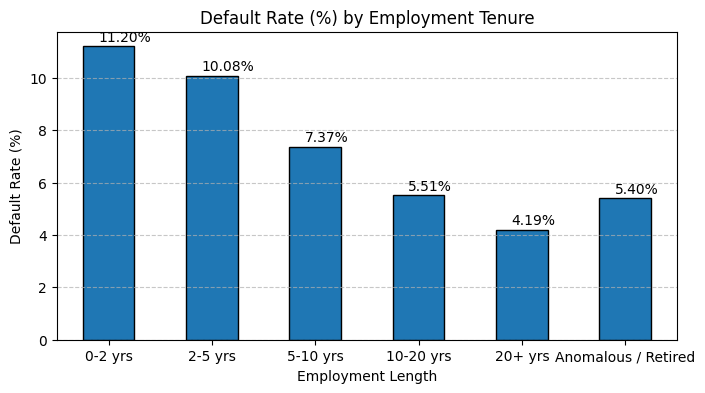

In [12]:
import matplotlib.pyplot as plt

# 1. Create positive employment years
df_plot = application_train[['TARGET', 'DAYS_EMPLOYED', 'DAYS_EMPLOYED_ANOM']].copy()
df_plot['YEARS_EMPLOYED'] = -df_plot['DAYS_EMPLOYED'] / 365

# 2. Cut into tenure bins (labeling the 365243 anomalies separately)
bins = [0, 2, 5, 10, 20, 50]
labels = ['0-2 yrs', '2-5 yrs', '5-10 yrs', '10-20 yrs', '20+ yrs']
df_plot['TENURE_BIN'] = pd.cut(df_plot['YEARS_EMPLOYED'], bins=bins, labels=labels)
df_plot['TENURE_BIN'] = df_plot['TENURE_BIN'].cat.add_categories('Anomalous / Retired')
df_plot.loc[df_plot['DAYS_EMPLOYED_ANOM'] == 1, 'TENURE_BIN'] = 'Anomalous / Retired'

# 3. Calculate default rate per bin and plot
default_by_tenure = df_plot.groupby('TENURE_BIN', observed=False)['TARGET'].mean() * 100

ax = default_by_tenure.plot(kind='bar', color='#1f77b4', figsize=(8, 4), edgecolor='black')
plt.title('Default Rate (%) by Employment Tenure', fontsize=12)
plt.ylabel('Default Rate (%)')
plt.xlabel('Employment Length')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Print values on bars
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%", (p.get_x() + 0.15, p.get_height() + 0.2))

plt.show()

In [13]:
# 1. Debt-to-Income: Leverage relative to annual earnings
application_train['RATIO_CREDIT_TO_INCOME'] = (
    application_train['AMT_CREDIT'] / application_train['AMT_INCOME_TOTAL']
)

# 2. Payment Burden: Cash flow pressure per payment period (Payment Burden / Cash Flow Strain)
application_train['RATIO_ANNUITY_TO_INCOME'] = (
    application_train['AMT_ANNUITY'] / application_train['AMT_INCOME_TOTAL']
)

# 3. Implied Loan Term: Approximate duration in payment cycles
application_train['RATIO_CREDIT_TO_ANNUITY'] = (
    application_train['AMT_CREDIT'] / application_train['AMT_ANNUITY']
)

In [14]:
application_train.RATIO_CREDIT_TO_INCOME.describe()

count    307511.000000
mean          3.957570
std           2.689728
min           0.004808
25%           2.018667
50%           3.265067
75%           5.159880
max          84.736842
Name: RATIO_CREDIT_TO_INCOME, dtype: float64

In [15]:
application_train.RATIO_ANNUITY_TO_INCOME.describe()

count    307499.000000
mean          0.180930
std           0.094574
min           0.000224
25%           0.114782
50%           0.162833
75%           0.229067
max           1.875965
Name: RATIO_ANNUITY_TO_INCOME, dtype: float64

In [16]:
application_train.RATIO_CREDIT_TO_ANNUITY.describe()

count    307499.000000
mean         21.612322
std           7.823823
min           8.036674
25%          15.614496
50%          20.000000
75%          27.099985
max          45.305079
Name: RATIO_CREDIT_TO_ANNUITY, dtype: float64

In [17]:
ratio_cols = [
    'RATIO_CREDIT_TO_INCOME',
    'RATIO_ANNUITY_TO_INCOME',
    'RATIO_CREDIT_TO_ANNUITY'
]

# Check for infinities (e.g. division by 0) and NaNs
health_check = pd.DataFrame({
    'NaN_Count': application_train[ratio_cols].isna().sum(),
    'Inf_Count': np.isinf(application_train[ratio_cols]).sum(),
    'NaN_%': (application_train[ratio_cols].isna().mean() * 100).round(4),
    'Inf_%': (np.isinf(application_train[ratio_cols]).mean() * 100).round(4)
})
print(health_check)

                         NaN_Count  Inf_Count   NaN_%  Inf_%
RATIO_CREDIT_TO_INCOME           0          0  0.0000    0.0
RATIO_ANNUITY_TO_INCOME         12          0  0.0039    0.0
RATIO_CREDIT_TO_ANNUITY         12          0  0.0039    0.0


In [18]:
percentiles = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999]
application_train[ratio_cols].describe(percentiles=percentiles).T[
    ['count', 'mean', 'std', 'min', '1%', '50%', '95%', '99%', '99.9%', 'max']
]

,count,mean,std,min,1%,50%,95%,99%,99.9%,max
RATIO_CREDIT_TO_INCOME,307511.0,3.957570,2.689728,0.004808,0.595365,3.265067,9.156739,13.027280,19.293778,84.736842
RATIO_ANNUITY_TO_INCOME,307499.0,0.180930,0.094574,0.000224,0.039474,0.162833,0.354667,0.483458,0.727986,1.875965
RATIO_CREDIT_TO_ANNUITY,307499.0,21.612322,7.823823,8.036674,8.709985,20.000000,34.542314,37.794118,37.915633,45.305079


In [19]:
import lightgbm as lgb
from sklearn.metrics import roc_auc_score

# 1. Define Kolmogorov-Smirnov (KS) metric function
def calculate_ks_statistic(y_true, y_pred_prob):
    """
    Computes the maximum separation between cumulative true positive 
    and cumulative false positive rates across ranked predictions.
    """
    df = pd.DataFrame({'target': y_true, 'prob': y_pred_prob})
    df = df.sort_values('prob', ascending=False).reset_index(drop=True)
    
    total_defaulters = df['target'].sum()
    total_repayers = len(df) - total_defaulters
    
    cum_defaulters = df['target'].cumsum() / total_defaulters
    cum_repayers = (1 - df['target']).cumsum() / total_repayers
    
    ks_curve = np.abs(cum_defaulters - cum_repayers)
    return ks_curve.max() * 100

# 2. Prepare feature matrix and handle categorical datatypes
# Drop non-feature administrative columns
drop_cols = ['TARGET', 'SK_ID_CURR', 'fold']
feature_cols = [col for col in application_train.columns if col not in drop_cols]

# Cast object columns to 'category' for native LightGBM histogram binning
categorical_cols = application_train[feature_cols].select_dtypes(include=['object']).columns.tolist()
for c in categorical_cols:
    application_train[c] = application_train[c].astype('category')

# 3. Initialize container for out-of-fold (OOF) predictions
oof_predictions = np.zeros(len(application_train))
fold_metrics = []

# 4. Train 5-fold baseline models
for fold in range(5):
    # Slice training and validation sets using the pre-assigned fold column
    train_mask = application_train['fold'] != fold
    val_mask = application_train['fold'] == fold
    
    X_train, y_train = application_train.loc[train_mask, feature_cols], application_train.loc[train_mask, 'TARGET']
    X_val, y_val = application_train.loc[val_mask, feature_cols], application_train.loc[val_mask, 'TARGET']
    
    # Conservative baseline configuration to prevent premature overfitting
    clf = lgb.LGBMClassifier(
        n_estimators=1000,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=0.1,
        random_state=42,
        n_jobs=-1,
        importance_type='gain'
    )
    
    # Train with early stopping monitoring validation ROC-AUC
    clf.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        eval_metric='auc',
        callbacks=[
            lgb.early_stopping(stopping_rounds=50, verbose=False),
            lgb.log_evaluation(period=0)
        ]
    )
    
    # Predict probabilities for the held-out fold
    val_preds = clf.predict_proba(X_val)[:, 1]
    oof_predictions[val_mask] = val_preds
    
    # Calculate fold-level metrics
    fold_auc = roc_auc_score(y_val, val_preds)
    fold_ks = calculate_ks_statistic(y_val, val_preds)
    fold_metrics.append({'fold': fold, 'auc': fold_auc, 'ks': fold_ks})
    
    print(f"Fold {fold} | Validation ROC-AUC: {fold_auc:.5f} | KS: {fold_ks:.2f}%")

# 5. Evaluate Overall Out-of-Fold (OOF) Performance
overall_auc = roc_auc_score(application_train['TARGET'], oof_predictions)
overall_ks = calculate_ks_statistic(application_train['TARGET'], oof_predictions)

print("\n" + "="*45)
print(f"OVERALL OOF ROC-AUC : {overall_auc:.5f}")
print(f"OVERALL OOF KS      : {overall_ks:.2f}%")
print("="*45)

[LightGBM] [Info] Number of positive: 19860, number of negative: 226148
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.085425 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 12119
[LightGBM] [Info] Number of data points in the train set: 246008, number of used features: 120
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432482
[LightGBM] [Info] Start training from score -2.432482
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best

In [20]:
# Average feature importances across the 5 trained folds
feature_importances = pd.DataFrame({
    'feature': feature_cols,
    'importance': clf.feature_importances_
}).sort_values('importance', ascending=False)

print(feature_importances.head(10))

                     feature    importance
41              EXT_SOURCE_3  62658.316543
40              EXT_SOURCE_2  55410.292156
123  RATIO_CREDIT_TO_ANNUITY  21970.812789
38         ORGANIZATION_TYPE  21573.021634
39              EXT_SOURCE_1  20667.839179
16             DAYS_EMPLOYED   9707.550309
15                DAYS_BIRTH   6674.295797
26           OCCUPATION_TYPE   5923.269317
7                AMT_ANNUITY   5065.161152
8            AMT_GOODS_PRICE   4913.310188


- The Consensus Rating (MEAN): In retail underwriting, taking the average across multiple reporting agencies smooths individual reporting biases and produces a unified credit rating.

- The "Weakest Link" Rule (MIN): Lenders care disproportionately about the worst report. If two agencies show a clean profile but the third flags a delinquency, the applicant represents a high-risk borrower.

- Credit File Depth (COUNT): Whether a borrower has records in 1, 2, or all 3 agencies indicates credit history maturity. An applicant with only 1 bureau hit has a "thin file" (high uncertainty), whereas 3 hits indicate established borrowing history.

- Bureau Disagreement (STD): High variance across bureau scores indicates conflicting records, reporting delays, or volatile repayment behavior across different creditor types.

- Joint Risk Compounding (PROD): Since these normalized scores range between 0 and 1, their product plummets toward zero when even one bureau flags severe impairment.

In [21]:
# creating interaction features
ext_cols = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']

# 1. Central tendency and dispersion across available bureaus
application_train['EXT_SOURCES_MEAN'] = application_train[ext_cols].mean(axis=1)
application_train['EXT_SOURCES_STD'] = application_train[ext_cols].std(axis=1)
application_train['EXT_SOURCES_MIN'] = application_train[ext_cols].min(axis=1)
application_train['EXT_SOURCES_MAX'] = application_train[ext_cols].max(axis=1)

# 2. File maturity: count of bureaus reporting on the applicant
application_train['EXT_SOURCES_COUNT'] = application_train[ext_cols].notna().sum(axis=1)

# 3. Compound interaction
application_train['EXT_SOURCES_PROD'] = (
    application_train['EXT_SOURCE_1'] * 
    application_train['EXT_SOURCE_2'] * 
    application_train['EXT_SOURCE_3']
)

# 4. Age-adjusted bureau profile (score maturity relative to life stage)
application_train['EXT_SOURCE_TO_AGE'] = (
    application_train['EXT_SOURCES_MEAN'] / (-application_train['DAYS_BIRTH'] / 365)
)

In [22]:
# re-running the cross validation benchmark
# Refresh feature column list to include the newly engineered interactions
drop_cols = ['TARGET', 'SK_ID_CURR', 'fold']
feature_cols = [col for col in application_train.columns if col not in drop_cols]

oof_predictions_v2 = np.zeros(len(application_train))
fold_metrics_v2 = []

for fold in range(5):
    train_mask = application_train['fold'] != fold
    val_mask = application_train['fold'] == fold
    
    X_train, y_train = application_train.loc[train_mask, feature_cols], application_train.loc[train_mask, 'TARGET']
    X_val, y_val = application_train.loc[val_mask, feature_cols], application_train.loc[val_mask, 'TARGET']
    
    clf = lgb.LGBMClassifier(
        n_estimators=1000,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=0.1,
        random_state=42,
        n_jobs=-1,
        importance_type='gain'
    )
    
    clf.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        eval_metric='auc',
        callbacks=[
            lgb.early_stopping(stopping_rounds=50, verbose=False),
            lgb.log_evaluation(period=0)
        ]
    )
    
    val_preds = clf.predict_proba(X_val)[:, 1]
    oof_predictions_v2[val_mask] = val_preds
    
    fold_auc = roc_auc_score(y_val, val_preds)
    fold_ks = calculate_ks_statistic(y_val, val_preds)
    fold_metrics_v2.append({'fold': fold, 'auc': fold_auc, 'ks': fold_ks})
    
    print(f"Fold {fold} | Validation ROC-AUC: {fold_auc:.5f} | KS: {fold_ks:.2f}%")

overall_auc_v2 = roc_auc_score(application_train['TARGET'], oof_predictions_v2)
overall_ks_v2 = calculate_ks_statistic(application_train['TARGET'], oof_predictions_v2)

print("\n" + "="*45)
print(f"PREVIOUS OOF ROC-AUC : 0.76694 | KS: 39.74%")
print(f"UPDATED  OOF ROC-AUC : {overall_auc_v2:.5f} | KS: {overall_ks_v2:.2f}%")
print(f"DELTA                : +{overall_auc_v2 - 0.76694:.5f} AUC")
print("="*45)

[LightGBM] [Info] Number of positive: 19860, number of negative: 226148
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.084951 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 13653
[LightGBM] [Info] Number of data points in the train set: 246008, number of used features: 127
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432482
[LightGBM] [Info] Start training from score -2.432482
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best

### Engineered several composite bureau interactions on application_train, but observed a negligible lift (+0.00005 AUC). Recognizing that the static application table had reached its predictive limit around 0.767 AUC, we avoided accumulating collinear technical debt and shifted our engineering focus to relational transactional history.

In [23]:
# importing bureau.csv
bureau=pd.read_csv('/kaggle/input/datasets/megancrenshaw/home-credit-default-risk/bureau.csv')

In [24]:
bureau.shape

(1716428, 17)

In [25]:
bureau.sample(5)

,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
426096,158849,5747569,Closed,currency 1,-1115,0,-325.0,-325.0,NaN,0,585000.0,0.0,0.0,0.0,Consumer credit,-309,NaN
1025717,388706,5887166,Closed,currency 1,-801,0,-497.0,-491.0,6748.65,0,63855.0,0.0,0.0,0.0,Consumer credit,-490,NaN
221126,368368,5709691,Closed,currency 1,-2451,0,-1356.0,-1452.0,NaN,0,225000.0,0.0,0.0,0.0,Consumer credit,-252,0.0
580845,250563,6447258,Active,currency 1,-785,0,1003.0,NaN,NaN,0,1053000.0,973188.0,NaN,0.0,Credit card,-21,NaN
1433265,194496,6721286,Active,currency 1,-154,0,151.0,NaN,NaN,0,64732.5,40396.5,0.0,0.0,Consumer credit,-30,NaN


In [26]:
bureau.columns

Index(['SK_ID_CURR', 'SK_ID_BUREAU', 'CREDIT_ACTIVE', 'CREDIT_CURRENCY',
       'DAYS_CREDIT', 'CREDIT_DAY_OVERDUE', 'DAYS_CREDIT_ENDDATE',
       'DAYS_ENDDATE_FACT', 'AMT_CREDIT_MAX_OVERDUE', 'CNT_CREDIT_PROLONG',
       'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT',
       'AMT_CREDIT_SUM_OVERDUE', 'CREDIT_TYPE', 'DAYS_CREDIT_UPDATE',
       'AMT_ANNUITY'],
      dtype='object')

The Aggregation Strategy
To bring this external borrowing history into your model without breaking the 1-row-per-applicant grain, you must group by SK_ID_CURR and aggregate into summary statistics before joining:

- Total number of external loans per applicant (count of SK_ID_BUREAU).

- Total current outstanding debt (sum of AMT_CREDIT_SUM_DEBT).

- Number of currently Active vs Closed credit lines.

- Longest overdue duration across all external accounts (max of CREDIT_DAY_OVERDUE).

In [27]:
bureau_agg_spec = {
    'SK_ID_BUREAU': ['count'],
    'AMT_CREDIT_SUM_DEBT': ['sum', 'max'],
    'CNT_CREDIT_PROLONG': ['sum', 'max'],
    'CREDIT_DAY_OVERDUE': ['max'],
    'DAYS_CREDIT': ['max', 'min', 'mean']
}

# 1. Group by applicant ID and aggregate
bureau_agg = bureau.groupby('SK_ID_CURR').agg(bureau_agg_spec)

# 2. Flatten MultiIndex column names (e.g., ('DAYS_CREDIT', 'max') -> 'BUREAU_DAYS_CREDIT_MAX')
bureau_agg.columns = ['BUREAU_' + '_'.join(col).upper() for col in bureau_agg.columns]
bureau_agg = bureau_agg.reset_index()

print("Aggregated shape:", bureau_agg.shape)
bureau_agg.head()

Aggregated shape: (305811, 10)


,SK_ID_CURR,BUREAU_SK_ID_BUREAU_COUNT,BUREAU_AMT_CREDIT_SUM_DEBT_SUM,BUREAU_AMT_CREDIT_SUM_DEBT_MAX,BUREAU_CNT_CREDIT_PROLONG_SUM,BUREAU_CNT_CREDIT_PROLONG_MAX,BUREAU_CREDIT_DAY_OVERDUE_MAX,BUREAU_DAYS_CREDIT_MAX,BUREAU_DAYS_CREDIT_MIN,BUREAU_DAYS_CREDIT_MEAN
0,100001,7,596686.5,373239.0,0,0,0,-49,-1572,-735.000000
1,100002,8,245781.0,245781.0,0,0,0,-103,-1437,-874.000000
2,100003,4,0.0,0.0,0,0,0,-606,-2586,-1400.750000
3,100004,2,0.0,0.0,0,0,0,-408,-1326,-867.000000
4,100005,3,568408.5,543087.0,0,0,0,-62,-373,-190.666667


In [28]:
# 1. Left merge bureau features onto application_train
application_train = application_train.merge(bureau_agg, on='SK_ID_CURR', how='left')

# 2. Fill loan count: missing record = 0 prior bureau loans
application_train['BUREAU_SK_ID_BUREAU_COUNT'] = application_train['BUREAU_SK_ID_BUREAU_COUNT'].fillna(0)

# 3. Check how many applicants in application_train have zero bureau history
no_bureau_count = (application_train['BUREAU_SK_ID_BUREAU_COUNT'] == 0).sum()
print(f"Applicants with ZERO external bureau history: {no_bureau_count:,} ({no_bureau_count / len(application_train) * 100:.2f}%)")
print("Updated application_train shape:", application_train.shape)

Applicants with ZERO external bureau history: 44,020 (14.31%)
Updated application_train shape: (307511, 143)


In [29]:
# Refresh feature columns to capture the new BUREAU_ columns
drop_cols = ['TARGET', 'SK_ID_CURR', 'fold']
feature_cols = [col for col in application_train.columns if col not in drop_cols]

oof_predictions_bureau = np.zeros(len(application_train))

for fold in range(5):
    train_mask = application_train['fold'] != fold
    val_mask = application_train['fold'] == fold
    
    X_train, y_train = application_train.loc[train_mask, feature_cols], application_train.loc[train_mask, 'TARGET']
    X_val, y_val = application_train.loc[val_mask, feature_cols], application_train.loc[val_mask, 'TARGET']
    
    clf = lgb.LGBMClassifier(
        n_estimators=1000,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=0.1,
        random_state=42,
        n_jobs=-1,
        importance_type='gain'
    )
    
    clf.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        eval_metric='auc',
        callbacks=[
            lgb.early_stopping(stopping_rounds=50, verbose=False),
            lgb.log_evaluation(period=0)
        ]
    )
    
    val_preds = clf.predict_proba(X_val)[:, 1]
    oof_predictions_bureau[val_mask] = val_preds
    
    fold_auc = roc_auc_score(y_val, val_preds)
    fold_ks = calculate_ks_statistic(y_val, val_preds)
    print(f"Fold {fold} | Validation ROC-AUC: {fold_auc:.5f} | KS: {fold_ks:.2f}%")

overall_auc_bureau = roc_auc_score(application_train['TARGET'], oof_predictions_bureau)
overall_ks_bureau = calculate_ks_statistic(application_train['TARGET'], oof_predictions_bureau)

print("\n" + "="*45)
print(f"BASELINE OOF ROC-AUC : 0.76694 | KS: 39.74%")
print(f"BUREAU   OOF ROC-AUC : {overall_auc_bureau:.5f} | KS: {overall_ks_bureau:.2f}%")
print(f"DELTA                : +{overall_auc_bureau - 0.76694:.5f} AUC")
print("="*45)

[LightGBM] [Info] Number of positive: 19860, number of negative: 226148
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.081375 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 15251
[LightGBM] [Info] Number of data points in the train set: 246008, number of used features: 136
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432482
[LightGBM] [Info] Start training from score -2.432482
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best

In [30]:
# Check where the new bureau features land in the top 20
feature_importances_bureau = pd.DataFrame({
    'feature': feature_cols,
    'importance': clf.feature_importances_
}).sort_values('importance', ascending=False).reset_index(drop=True)

print(feature_importances_bureau[feature_importances_bureau['feature'].str.startswith('BUREAU_')].head(5))

                           feature   importance
7           BUREAU_DAYS_CREDIT_MAX  6214.764049
15  BUREAU_AMT_CREDIT_SUM_DEBT_SUM  4255.934807
17         BUREAU_DAYS_CREDIT_MEAN  4191.071808
24  BUREAU_AMT_CREDIT_SUM_DEBT_MAX  2936.912240
29          BUREAU_DAYS_CREDIT_MIN  2124.568688


In [33]:
print([col for col in application_train.columns if 'BUREAU_ACTIVE' in col])

['BUREAU_ACTIVE_SK_ID_BUREAU_COUNT_x', 'BUREAU_ACTIVE_AMT_CREDIT_SUM_DEBT_SUM_x', 'BUREAU_ACTIVE_AMT_CREDIT_SUM_DEBT_MAX_x', 'BUREAU_ACTIVE_AMT_CREDIT_SUM_SUM_x', 'BUREAU_ACTIVE_DAYS_CREDIT_MAX_x', 'RATIO_BUREAU_ACTIVE_LOANS', 'BUREAU_ACTIVE_SK_ID_BUREAU_COUNT_y', 'BUREAU_ACTIVE_AMT_CREDIT_SUM_DEBT_SUM_y', 'BUREAU_ACTIVE_AMT_CREDIT_SUM_DEBT_MAX_y', 'BUREAU_ACTIVE_AMT_CREDIT_SUM_SUM_y', 'BUREAU_ACTIVE_DAYS_CREDIT_MAX_y']


In [34]:
# 1. Clean up any existing BUREAU_ACTIVE columns or duplicate suffixes
cols_to_drop = [col for col in application_train.columns if 'BUREAU_ACTIVE' in col]
if cols_to_drop:
    application_train.drop(columns=cols_to_drop, inplace=True)

# 2. Filter specifically for active bureau accounts
bureau_active = bureau[bureau['CREDIT_ACTIVE'] == 'Active']

# 3. Aggregate active-specific metrics
active_agg = bureau_active.groupby('SK_ID_CURR').agg({
    'SK_ID_BUREAU': ['count'],
    'AMT_CREDIT_SUM_DEBT': ['sum', 'max'],
    'AMT_CREDIT_SUM': ['sum'],
    'DAYS_CREDIT': ['max']
})

# Flatten MultiIndex column names
active_agg.columns = ['BUREAU_ACTIVE_' + '_'.join(col).upper() for col in active_agg.columns]
active_agg = active_agg.reset_index()

# 4. Clean left-join
application_train = application_train.merge(active_agg, on='SK_ID_CURR', how='left')

# 5. Handle missingness for borrowers with no active loans
application_train['BUREAU_ACTIVE_SK_ID_BUREAU_COUNT'] = (
    application_train['BUREAU_ACTIVE_SK_ID_BUREAU_COUNT'].fillna(0)
)
application_train['BUREAU_ACTIVE_AMT_CREDIT_SUM_DEBT_SUM'] = (
    application_train['BUREAU_ACTIVE_AMT_CREDIT_SUM_DEBT_SUM'].fillna(0)
)

# 6. Engineer active ratio and systemic debt-to-income
application_train['RATIO_BUREAU_ACTIVE_LOANS'] = (
    application_train['BUREAU_ACTIVE_SK_ID_BUREAU_COUNT'] / 
    application_train['BUREAU_SK_ID_BUREAU_COUNT'].replace({0: np.nan})
)

application_train['RATIO_TOTAL_SYSTEM_DEBT_TO_INCOME'] = (
    (application_train['AMT_CREDIT'] + application_train['BUREAU_ACTIVE_AMT_CREDIT_SUM_DEBT_SUM']) / 
    application_train['AMT_INCOME_TOTAL']
)

print("Merge and feature creation successful!")
print(f"Total columns now: {application_train.shape[1]}")

Merge and feature creation successful!
Total columns now: 150


In [37]:
# Refresh feature column list to include all 150 columns (excluding targets/admin)
drop_cols = ['TARGET', 'SK_ID_CURR', 'fold']
feature_cols = [col for col in application_train.columns if col not in drop_cols]

oof_predictions_v3 = np.zeros(len(application_train))
fold_metrics_v3 = []

for fold in range(5):
    train_mask = application_train['fold'] != fold
    val_mask = application_train['fold'] == fold
    
    X_train, y_train = application_train.loc[train_mask, feature_cols], application_train.loc[train_mask, 'TARGET']
    X_val, y_val = application_train.loc[val_mask, feature_cols], application_train.loc[val_mask, 'TARGET']
    
    clf = lgb.LGBMClassifier(
        n_estimators=1000,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=0.1,
        random_state=42,
        n_jobs=-1,
        importance_type='gain'
    )
    
    clf.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        eval_metric='auc',
        callbacks=[
            lgb.early_stopping(stopping_rounds=50, verbose=False),
            lgb.log_evaluation(period=0)
        ]
    )
    
    val_preds = clf.predict_proba(X_val)[:, 1]
    oof_predictions_v3[val_mask] = val_preds
    
    fold_auc = roc_auc_score(y_val, val_preds)
    fold_ks = calculate_ks_statistic(y_val, val_preds)
    fold_metrics_v3.append({'fold': fold, 'auc': fold_auc, 'ks': fold_ks})
    
    print(f"Fold {fold} | Validation ROC-AUC: {fold_auc:.5f} | KS: {fold_ks:.2f}%")

overall_auc_v3 = roc_auc_score(application_train['TARGET'], oof_predictions_v3)
overall_ks_v3 = calculate_ks_statistic(application_train['TARGET'], oof_predictions_v3)

print("\n" + "="*50)
print(f"BASELINE OOF ROC-AUC        : 0.76694 | KS: 39.74%")
print(f"BUREAU V1 (ALL LOANS)       : 0.76974 | KS: 40.20%")
print(f"BUREAU V2 (ACTIVE ISOLATED) : {overall_auc_v3:.5f} | KS: {overall_ks_v3:.2f}%")
print(f"DELTA OVER BASELINE         : +{overall_auc_v3 - 0.76694:.5f} AUC")
print(f"DELTA OVER BUREAU V1        : +{overall_auc_v3 - 0.76974:.5f} AUC")
print("="*50)

[LightGBM] [Info] Number of positive: 19860, number of negative: 226148
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.303383 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 17715
[LightGBM] [Info] Number of data points in the train set: 246008, number of used features: 148
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432482
[LightGBM] [Info] Start training from score -2.432482
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive

What Made the Active Split Work
- Elimination of "Good Debt" Noise: In the unsegmented bureau aggregation (BUREAU V1), an applicant with five fully repaid mortgages looked mathematically identical in credit volume to an applicant with five active credit cards maxed out. Isolating CREDIT_ACTIVE == 'Active' prevented settled accounts from masking open risk.

- System-Wide Solvency (RATIO_TOTAL_SYSTEM_DEBT_TO_INCOME): The root table only evaluated whether the borrower could afford this new loan installment. Systemic DTI answers the real underwriting question: “Can this applicant service their entire debt load across every bank in the market simultaneously?”

- Active Exposure Ratio (RATIO_BUREAU_ACTIVE_LOANS): An applicant with 10 total loans where only 1 is active has demonstrated a 90% completion rate. An applicant with 4 total loans where all 4 are active has a 100% open exposure rate and has never proven they can settle a facility to zero.